Students are advised to review and adhere to the submission requirements documented after the assessment task. 

This is an individual Assessment using the PYTHON programming language. Develop and deploy unsupervised machine learning models in any one of the following areas only and analyse the results.
●	Transport
●	Housing and Zoning
●	Stock market dataset (only from last 10 years) from only website: https://finance.yahoo.com/quote/CSV/history/ 
The dataset should have a decent number of rows and columns, such as minimum 7 columns (for example, type of variables may be categorical, continuous, and discrete) after cleaning to justify the use of the machine learning modelling approach. The type of question(s) that you should formulate for the Assessment will depend on the chosen domain of the dataset as mentioned above. (Note: No marks will be awarded if the dataset is not based on the above-mentioned guidelines.)
Assessment questions could be: (this is a small, suggested, sample of questions, other questions may be more appropriate to your Assessment)

●	How to measure similarity or dissimilarity between different clusters?
●	Which clustering solution do you prefer, and why? 
●	How to analyse and investigate an inflation rate for a specific product from the provided time series dataset?  

You will present their findings and defend the results in the form of a poster presentation. Your poster should capture the following aspects that are relevant to your Assessment investigations. All practical implementations are carried in the Jupyter notebook (Note: The code in the form of Python files will not be accepted.)

i.	A precise introduction, motivation, description of problem domain, Assessment objectives and the rationale for the chosen dataset in the above-mentioned areas. 
(15 marks)
ii.	Which clustering algorithms would you consider for segmentation, and why? Implement the solutions and discuss the differences between silhouette score and Davies-Bouldin index in the context of clustering. Compare the results obtained from any two clustering algorithms from your own chosen dataset.
(30 marks)
iii.	Implement your solutions and discuss what insights can you derive from the initial exploration of the time series data based on the provided topics? Describe any trends, seasonality, or anomalies observed. How did you determine the appropriate parameters (p, d, q) for the ARIMA/ SARIMA model. Evaluate the performance of the ARIMA/ SARIMA model in forecasting future values, highlighting any strengths and limitations based on your chosen dataset.
(30 marks)
iv.	Interpret and justify the results based on the problem specification or Assessment objectives by using suitable visualizations. Comments and description of Python code, conclusions of the Assessment should be specified in the poster as well as in the Jupyter notebook. Citations and references should follow the Harvard style. You are required to record a video presentation to explain and justify your poster presentation and the code in the Jupyter Notebook. The video should not exceed 5 minutes in duration, and the use of AI-generated voices or agents is not permitted. The format of video recording is mentioned below


In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("hour.csv")

df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
print("Dataset shape:", df.shape)

Dataset shape: (17379, 17)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [5]:
print("Missing values by column:\n", df.isnull().sum())

print("\n Number of duplicated rows:", df.duplicated().sum())

Missing values by column:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

 Number of duplicated rows: 0


In [6]:
data = df.copy()

In [7]:
data["dteday"] = pd.to_datetime(data["dteday"])

data = data.sort_values(["dteday", "hr"]).reset_index(drop=True)

In [8]:
print("Start date:", data["dteday"].min())
print("End date:", data["dteday"].max())
print("Rows after sorting:", data.shape[0])

Start date: 2011-01-01 00:00:00
End date: 2012-12-31 00:00:00
Rows after sorting: 17379


In [9]:
data.describe()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045568,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599


<function matplotlib.pyplot.show(close=None, block=None)>

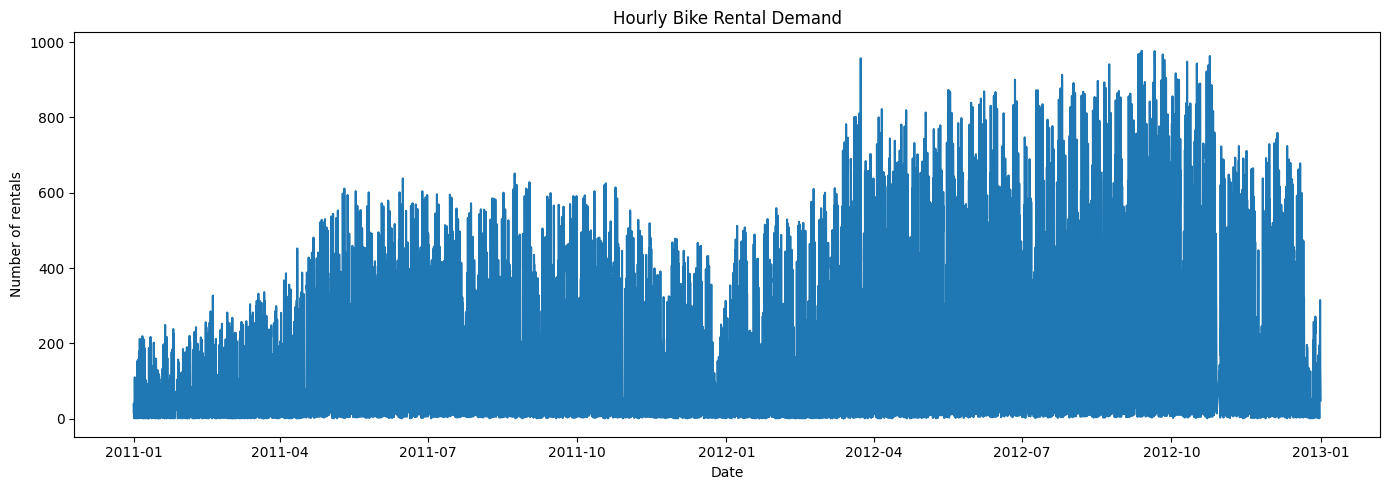

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(data["dteday"] + pd.to_timedelta(data["hr"], unit="h"), data["cnt"])
plt.title("Hourly Bike Rental Demand")
plt.xlabel("Date")
plt.ylabel("Number of rentals")
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

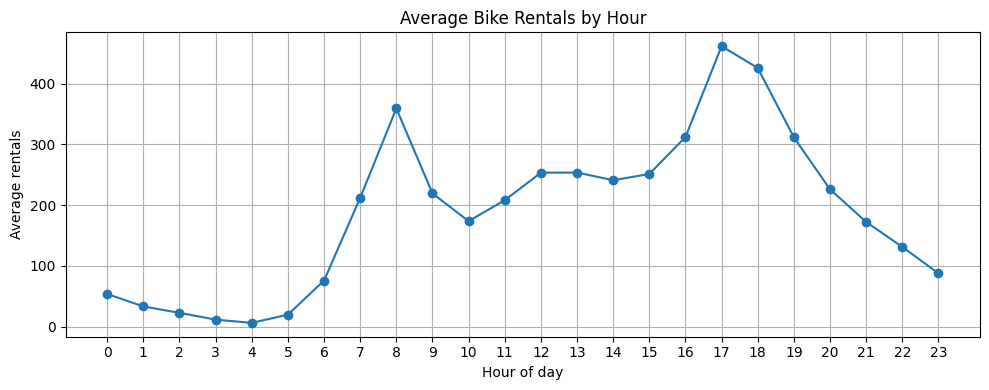

In [11]:
hourly_profile = data.groupby("hr")["cnt"].mean()

plt.figure(figsize=(10, 4))
plt.plot(hourly_profile.index, hourly_profile.values, marker="o")
plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Average rentals")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

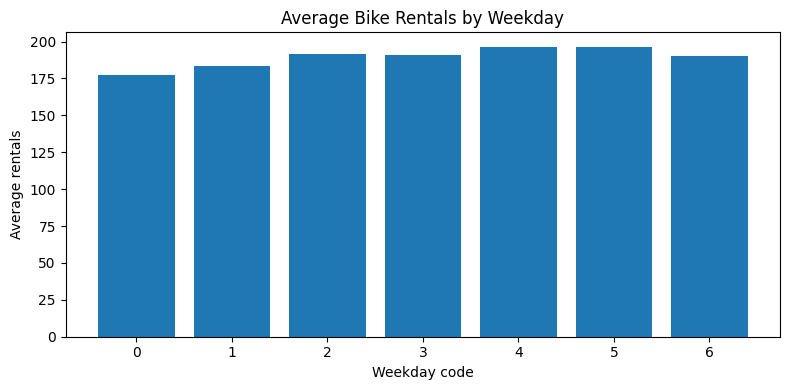

In [12]:
weekday_profile = data.groupby("weekday")["cnt"].mean()

plt.figure(figsize=(8, 4))
plt.bar(weekday_profile.index, weekday_profile.values)
plt.title("Average Bike Rentals by Weekday")
plt.xlabel("Weekday code")
plt.ylabel("Average rentals")
plt.tight_layout()
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

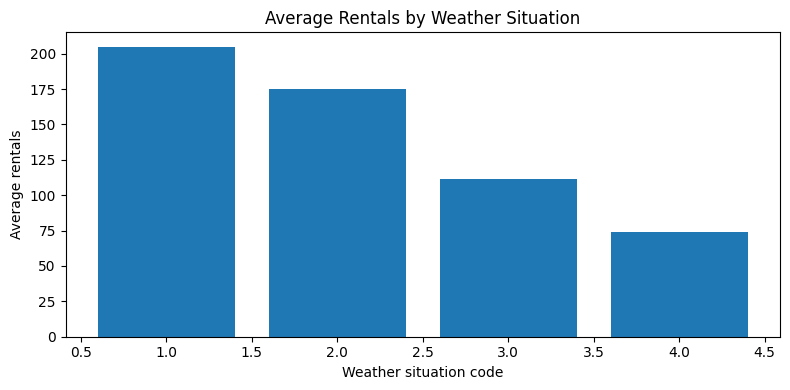

In [13]:
weather_profile = data.groupby("weathersit")["cnt"].mean()

plt.figure(figsize=(8, 4))
plt.bar(weather_profile.index, weather_profile.values)
plt.title("Average Rentals by Weather Situation")
plt.xlabel("Weather situation code")
plt.ylabel("Average rentals")
plt.tight_layout()
plt.show

In [14]:
cluster_features = ["hr", "temp", "hum", "windspeed", "cnt"]

X_cluster = data[cluster_features].copy()

X_cluster.head()

,hr,temp,hum,windspeed,cnt
0,0,0.24,0.81,0.0,16
1,1,0.22,0.80,0.0,40
2,2,0.22,0.80,0.0,32
3,3,0.24,0.75,0.0,13
4,4,0.24,0.75,0.0,1


In [15]:
X_cluster.describe()

,hr,temp,hum,windspeed,cnt
count,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,11.546752,0.496987,0.627229,0.190098,189.463088
std,6.914405,0.192556,0.192930,0.122340,181.387599
min,0.000000,0.020000,0.000000,0.000000,1.000000
25%,6.000000,0.340000,0.480000,0.104500,40.000000
50%,12.000000,0.500000,0.630000,0.194000,142.000000
75%,18.000000,0.660000,0.780000,0.253700,281.000000
max,23.000000,1.000000,1.000000,0.850700,977.000000


In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (17379, 5)


In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import random
random.seed(42)

sample_size = min(5000, len(X_scaled))
sample_indices = data.sample(n=sample_size, random_state=42).index
X_scaled_sample = X_scaled[sample_indices]

k_results = []

for k in range(2, 7):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    sample_labels = model.fit_predict(X_scaled_sample)

    sil = silhouette_score(X_scaled_sample, sample_labels)
    dbi = davies_bouldin_score(X_scaled_sample, sample_labels)

    k_results.append({
        "k": k,
        "Silhouette Score": sil,
        "Davies-Bouldin Index": dbi
    })

k_results_df = pd.DataFrame(k_results)

In [18]:
best_silhouette_k = int(k_results_df.loc[k_results_df["Silhouette Score"].idxmax(), "k"])
best_dbi_k = int(k_results_df.loc[k_results_df["Davies-Bouldin Index"].idxmin(), "k"])

display(k_results_df)

print("Best k by Silhouette Score:", best_silhouette_k)
print("Best k by Davies-Bouldin Index:", best_dbi_k)

,k,Silhouette Score,Davies-Bouldin Index
0,2,0.247803,1.557757
1,3,0.242677,1.526931
2,4,0.241434,1.364136
3,5,0.213892,1.427984
4,6,0.205395,1.510451


Best k by Silhouette Score: 2
Best k by Davies-Bouldin Index: 4


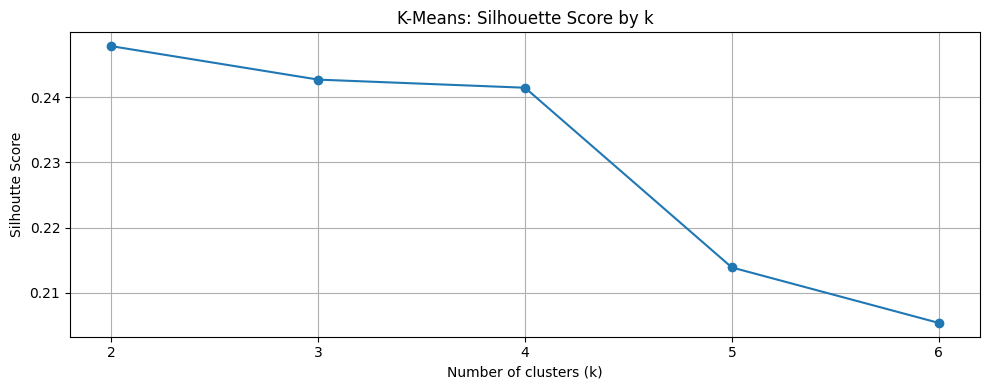

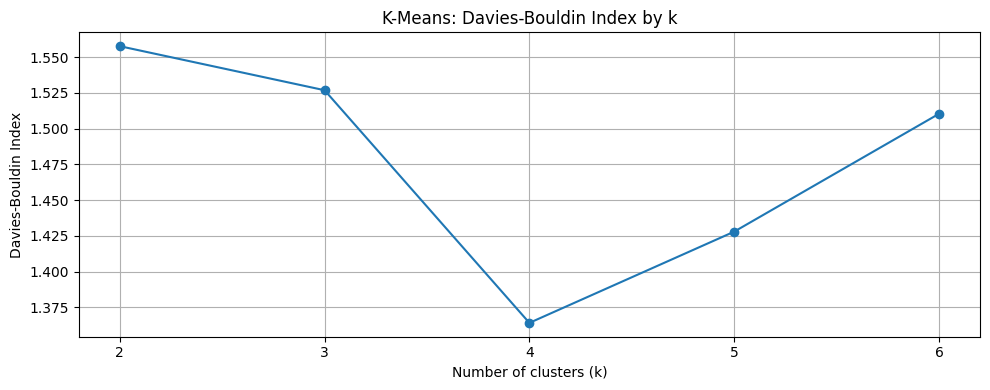

In [19]:
plt.figure(figsize=(10, 4))
plt.plot(k_results_df["k"], k_results_df["Silhouette Score"], marker="o")
plt.title("K-Means: Silhouette Score by k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhoutte Score")
plt.xticks(k_results_df["k"])
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(k_results_df["k"], k_results_df["Davies-Bouldin Index"], marker="o")
plt.title("K-Means: Davies-Bouldin Index by k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Davies-Bouldin Index")
plt.xticks(k_results_df["k"])
plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
candidate_k = [2, 3, 4]
candidate_results = []

for k in candidate_k:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    candidate_results.append({
        "k": k,
        "Silhouette Score": silhouette_score(X_scaled, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, labels), 
        "Smallest cluster size": pd.Series(labels).value_counts().min(),
        "Largest cluster size": pd.Series(labels).value_counts().max()
    })

candidate_results_df = pd.DataFrame(candidate_results)
display(candidate_results_df)

,k,Silhouette Score,Davies-Bouldin Index,Smallest cluster size,Largest cluster size
0,2,0.248296,1.551062,7924,9455
1,3,0.241193,1.530436,4935,6385
2,4,0.238698,1.371892,3279,5992


In [21]:
chosen_k = 4

In [22]:
from sklearn.cluster import AgglomerativeClustering

kmeans = KMeans(n_clusters=chosen_k, random_state=42, n_init=10)
data["kmeans_cluster"] = kmeans.fit_predict(X_scaled)

agg = AgglomerativeClustering(n_clusters=chosen_k, linkage="ward")
data["agg_cluster"] = agg.fit_predict(X_scaled)

print("Selected number of clusters (k):", chosen_k)

print("\nK-Means cluster sizes:")
print(data["kmeans_cluster"].value_counts().sort_index())

print("\nAgglomerative cluster sizes:")
print(data["agg_cluster"].value_counts().sort_index())

Selected number of clusters (k): 4

K-Means cluster sizes:
kmeans_cluster
0    5992
1    3517
2    4591
3    3279
Name: count, dtype: int64

Agglomerative cluster sizes:
agg_cluster
0    7052
1    4287
2    3732
3    2308
Name: count, dtype: int64


In [23]:
clustering_comparison = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Silhouette Score": silhouette_score(X_scaled, data["kmeans_cluster"]),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, data["kmeans_cluster"])
    },
    {
     "Algorithm": "Agglomerative Clustering",
        "Silhouette Score": silhouette_score(X_scaled, data["agg_cluster"]),
        "Davies-Bouldin Index": davies_bouldin_score(X_scaled, data["agg_cluster"])
    }
])
display(clustering_comparison)

,Algorithm,Silhouette Score,Davies-Bouldin Index
0,K-Means,0.238698,1.371892
1,Agglomerative Clustering,0.156832,1.766255


In [24]:
kmeans_profile = data.groupby("kmeans_cluster")[cluster_features].mean().round(3)
display(kmeans_profile)

agg_profile = data.groupby("agg_cluster")[cluster_features].mean().round(3)
display(agg_profile)

,hr,temp,hum,windspeed,cnt
kmeans_cluster,,,,,
0,4.471,0.459,0.766,0.135,66.923
1,12.357,0.344,0.463,0.312,144.366
2,14.490,0.684,0.507,0.200,405.551
3,19.488,0.468,0.718,0.147,159.212


,hr,temp,hum,windspeed,cnt
agg_cluster,,,,,
0,14.621,0.636,0.570,0.203,343.011
1,4.599,0.485,0.782,0.103,57.575
2,17.530,0.352,0.546,0.221,142.879
3,5.386,0.329,0.647,0.262,40.605


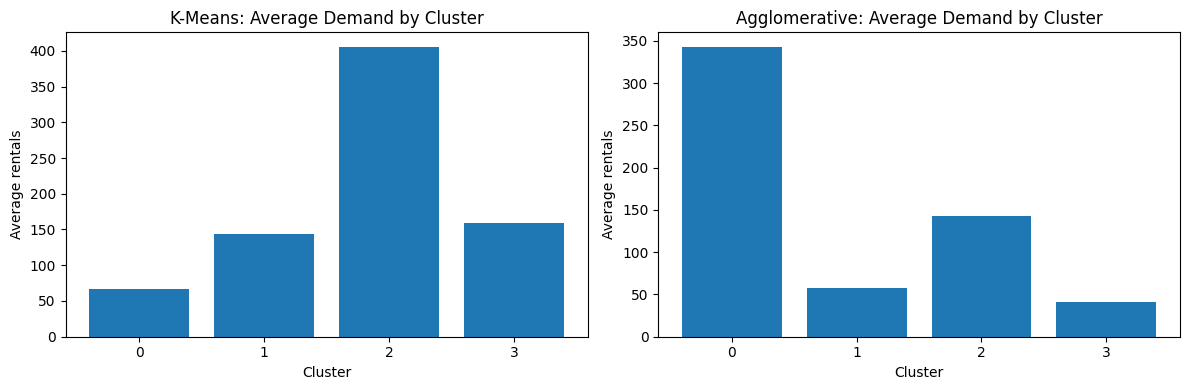

In [25]:
kmeans_demand = data.groupby("kmeans_cluster")["cnt"].mean()
agg_demand = data.groupby("agg_cluster")["cnt"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(kmeans_demand.index.astype(str), kmeans_demand.values)
axes[0].set_title("K-Means: Average Demand by Cluster")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Average rentals")

axes[1].bar(agg_demand.index.astype(str), agg_demand.values)
axes[1].set_title("Agglomerative: Average Demand by Cluster")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Average rentals")

plt.tight_layout()
plt.show()

In [26]:
daily = data.groupby("dteday", as_index=True)["cnt"].sum().sort_index()

full_date_index = pd.date_range(start=daily.index.min(), end=daily.index.max(), freq="D")
daily = daily.reindex(full_date_index)
daily.index.name = "dteday"

print("Daily observations expected:", len(daily))
print("Missing daily values after reindexing:", daily.isnull().sum())

if daily.isnull().sum() > 0:
    print("Missing dates detected.")
else:
    print("Daily series has no missing dates.")

display(daily.head())
display(daily.tail())
    

Daily observations expected: 731
Missing daily values after reindexing: 0
Daily series has no missing dates.


dteday
2011-01-01     985
2011-01-02     801
2011-01-03    1349
2011-01-04    1562
2011-01-05    1600
Freq: D, Name: cnt, dtype: int64

dteday
2012-12-27    2114
2012-12-28    3095
2012-12-29    1341
2012-12-30    1796
2012-12-31    2729
Freq: D, Name: cnt, dtype: int64

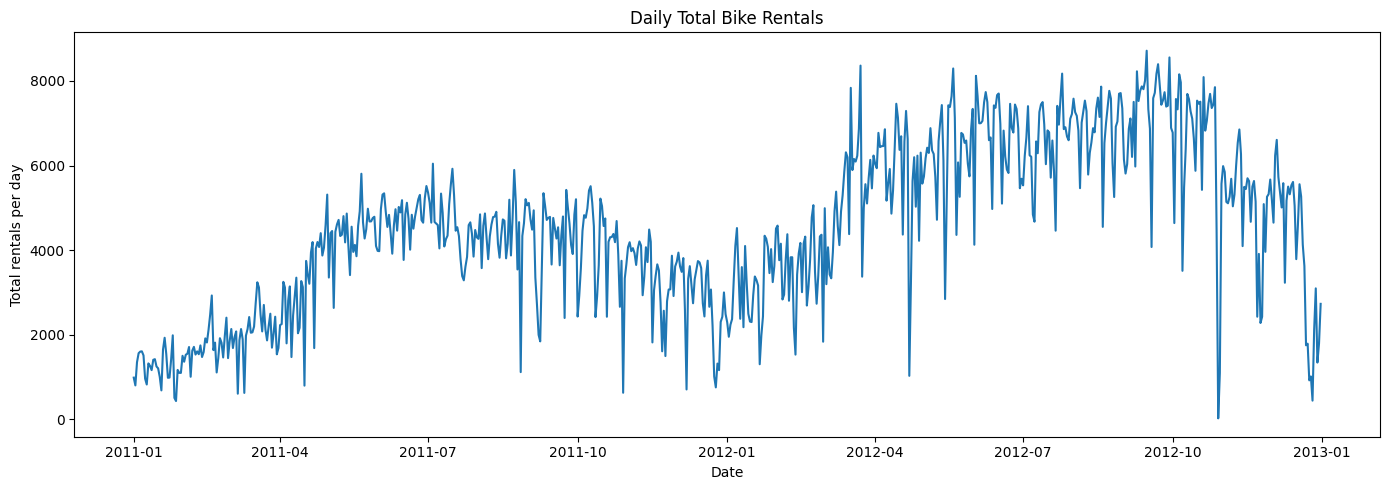

In [27]:
plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values)
plt.title("Daily Total Bike Rentals")
plt.xlabel("Date")
plt.ylabel("Total rentals per day")
plt.tight_layout()
plt.show()

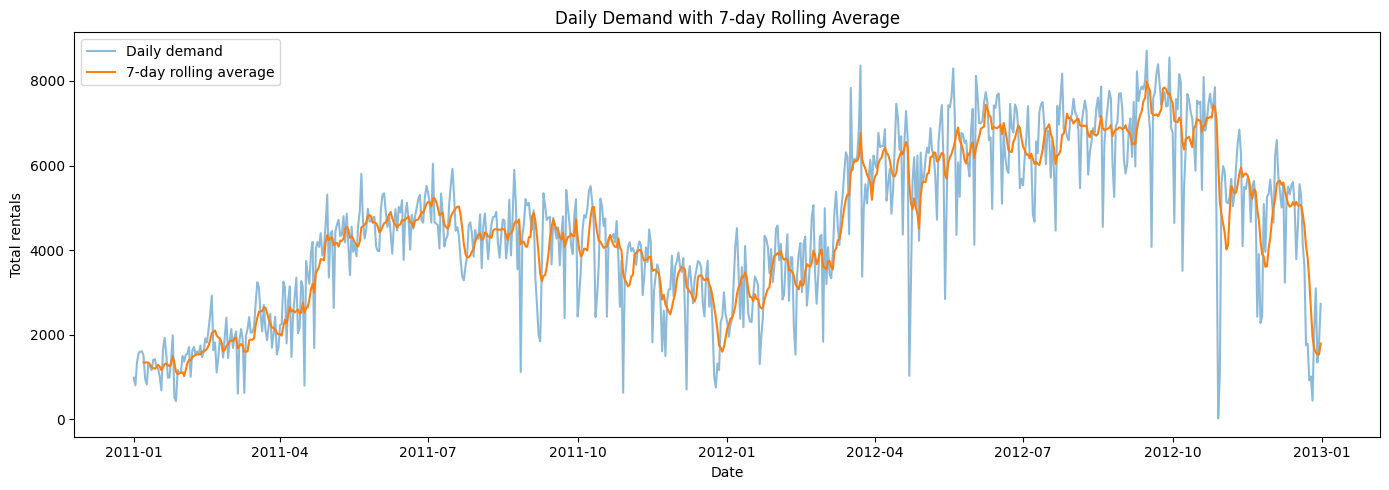

In [28]:
daily_rolling = daily.rolling(window=7).mean()

plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values, alpha=0.5, label="Daily demand")
plt.plot(daily_rolling.index, daily_rolling.values, label="7-day rolling average")
plt.title("Daily Demand with 7-day Rolling Average")
plt.xlabel("Date")
plt.ylabel("Total rentals")
plt.legend()
plt.tight_layout()
plt.show()

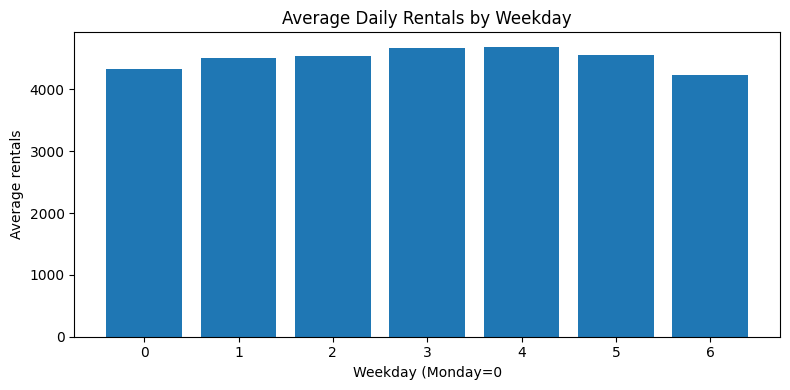

In [29]:
daily_frame = daily.to_frame(name="cnt")
daily_frame["weekday"] = daily_frame.index.dayofweek

daily_weekday_profile = daily_frame.groupby("weekday")["cnt"].mean()


plt.figure(figsize=(8, 4))
plt.bar(daily_weekday_profile.index, daily_weekday_profile.values)
plt.title("Average Daily Rentals by Weekday")
plt.xlabel("Weekday (Monday=0")
plt.ylabel("Average rentals")
plt.xticks(range(7))
plt.tight_layout()
plt.show()


In [30]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(daily.dropna())

print("ADF statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical values:", adf_result[4])


ADF statistic: -1.8774481444374291
p-value: 0.3427434403392198
Critical values: {'1%': np.float64(-3.439503230053971), '5%': np.float64(-2.8655794463678346), '10%': np.float64(-2.5689210707289982)}


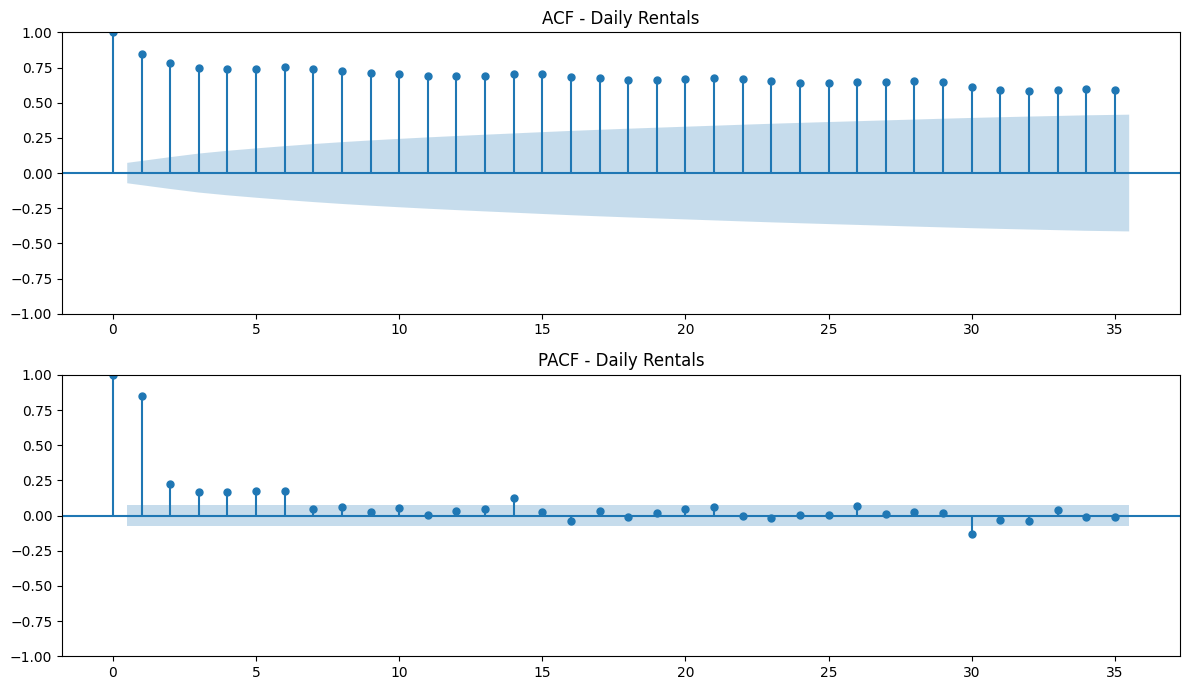

In [31]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

plot_acf(daily.dropna(), lags=35, ax=axes[0])
axes[0].set_title("ACF - Daily Rentals")

plot_pacf(daily.dropna(), lags=35, ax=axes[1], method="ywm")
axes[1].set_title("PACF - Daily Rentals")

plt.tight_layout()
plt.show()

Training obervations: 584
Testint observations: 147
Training period: 2011-01-01 00:00:00 to 2012-08-06 00:00:00
Testint period: 2012-08-07 00:00:00 to 2012-12-31 00:00:00


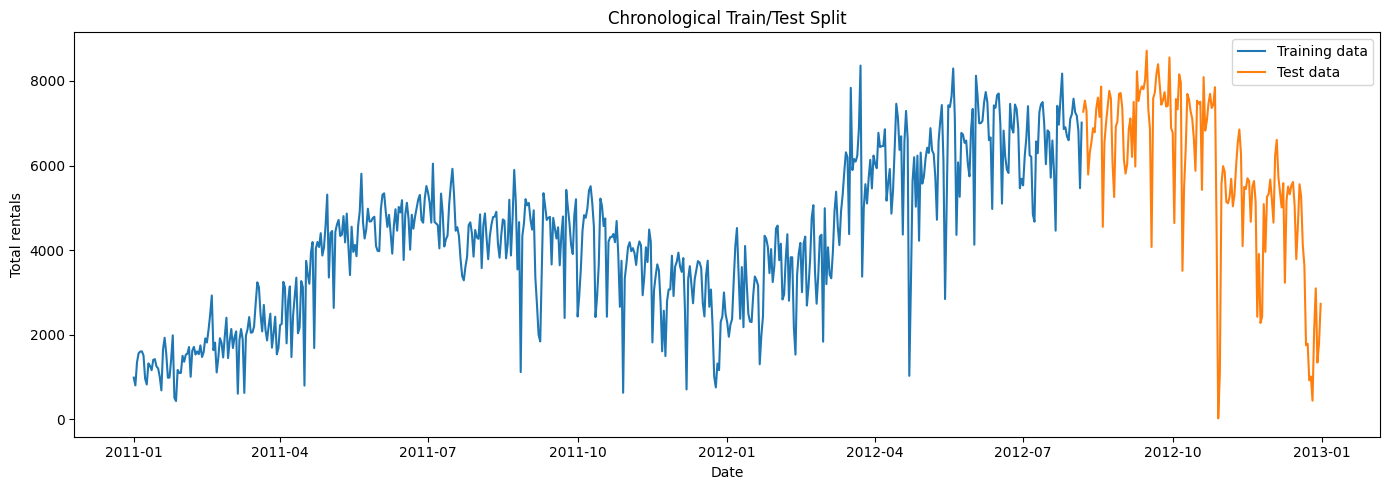

In [32]:
split_point = int(len(daily)*0.80)

train = daily.iloc[:split_point]
test = daily.iloc[split_point:]

print("Training obervations:", len(train))
print("Testint observations:", len(test))
print("Training period:", train.index.min(), "to", train.index.max())
print("Testint period:", test.index.min(), "to", test.index.max())

plt.figure(figsize=(14, 5))
plt.plot(train.index, train.values, label="Training data")
plt.plot(test.index, test.values, label="Test data")
plt.title("Chronological Train/Test Split")
plt.xlabel("Date")
plt.ylabel("Total rentals")
plt.legend()
plt.tight_layout()
plt.show()

In [40]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

validation_split = int(len(train)*0.80)
subtrain = train.iloc[:validation_split]
validation = train.iloc[validation_split:]

sarima_candidates = [
    ((1, 1, 1), (1, 1, 1, 7)),
    ((1, 1, 0), (1, 1, 0, 7)),
    ((2, 1, 1), (1, 1, 0, 7)),
    ((1, 0, 1), (1, 1, 0, 7)),
]

sarima_validation_results = []

for candidate_order, candidate_seasonal_order in sarima_candidates:
    try:
        candidate_model = SARIMAX(
            subtrain,
            order=candidate_order,
            seasonal_order=candidate_seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        candidate_fit = candidate_model.fit(disp=False)
        candidate_forecast = candidate_fit.get_forecast(steps=len(validation)).predicted_mean
        candidate_forecast.index = validation.index

        candidate_mae = mean_absolute_error(validation, candidate_forecast)
        candidate_rmse = mean_squared_error(validation, candidate_forecast)** 0.5

        sarima_validation_results.append({
            "order": candidate_order,
            "seasonal_order": candidate_seasonal_order,
            "Validation MAE": candidate_mae,
            "Validation RMSE": candidate_rmse,
            "Converged": candidate_fit.mle_retvals.get("converged", None)
        })
    except Exception as error:
        print("Candidate failed:", candidate_order, candidate_seasonal_order, error)

sarima_validation_df = pd.DataFrame(sarima_validation_results)
display(sarima_validation_df)

best_candidate_row = sarima_validation_df.loc[sarima_validation_df["Validation RMSE"].idxmin()]
order = best_candidate_row["order"]
seasonal_order = best_candidate_row["seasonal_order"]

print("Selected order:", order)
print("Selected seasonal_order:", seasonal_order)
print("Selection rule: lowest RMSE on the validation segment inside the training period.")

sarima_model = SARIMAX(
    train,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)
sarima_fit = sarima_model.fit(disp=False)
print(sarima_fit.summary())

,order,seasonal_order,Validation MAE,Validation RMSE,Converged
0,"(1, 1, 1)","(1, 1, 1, 7)",847.200771,1151.983731,True
1,"(1, 1, 0)","(1, 1, 0, 7)",5642.670217,6397.565153,True
2,"(2, 1, 1)","(1, 1, 0, 7)",1248.160528,1625.584215,True
3,"(1, 0, 1)","(1, 1, 0, 7)",1034.781178,1254.029402,True


Selected order: (1, 1, 1)
Selected seasonal_order: (1, 1, 1, 7)
Selection rule: lowest RMSE on the validation segment inside the training period.
                                     SARIMAX Results                                     
Dep. Variable:                               cnt   No. Observations:                  584
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood               -4638.789
Date:                           Wed, 28 Oct 2026   AIC                           9287.578
Time:                                   09:03:10   BIC                           9309.280
Sample:                               01-01-2011   HQIC                          9296.047
                                    - 08-06-2012                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------

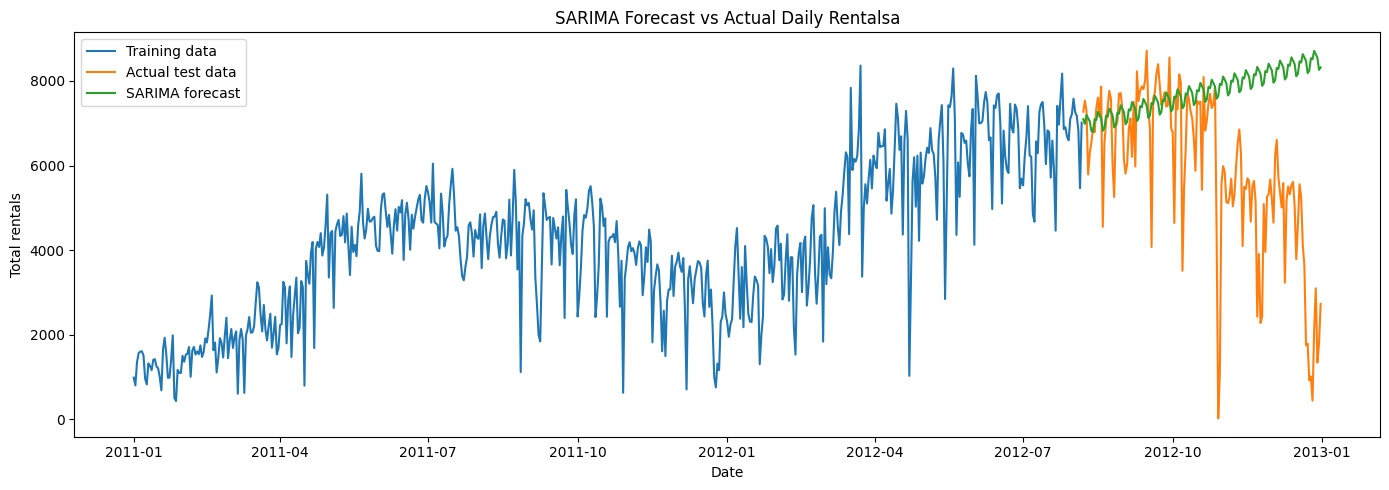

In [41]:
forecast_result = sarima_fit.get_forecast(steps=len(test))
forecast = forecast_result.predicted_mean

forecast.index = test.index

plt.figure(figsize=(14, 5))
plt.plot(train.index, train.values, label="Training data")
plt.plot(test.index, test.values, label="Actual test data")
plt.plot(forecast.index, forecast.values, label="SARIMA forecast")
plt.title("SARIMA Forecast vs Actual Daily Rentals")
plt.xlabel("Date")
plt.ylabel("Total rentals")
plt.legend()
plt.tight_layout()
plt.show()

In [42]:
mae = mean_absolute_error(test, forecast)
mse = mean_squared_error(test, forecast)
rmse = mse** 0.5

if (test != 0).all():
    mape = (abs((test - forecast) / test)).mean() * 100
else:
    mape = None

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
if mape is not None:
    print("MAPE (%):", round(mape, 3))
else:
    print("MAPE not calculated because at least one actual value is zero.")

MAE: 2034.394
RMSE: 2858.741
MAPE (%): 310.008


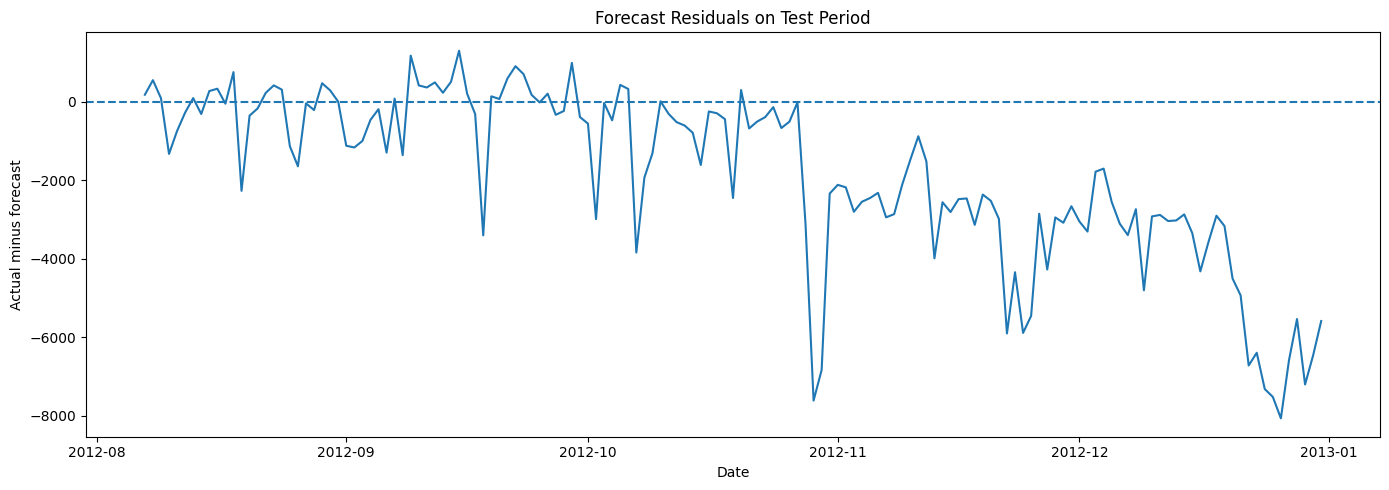

Mean test residual: -1849.164


In [43]:
residuals = test - forecast

plt.figure(figsize=(14, 5))
plt.plot(residuals.index, residuals.values)
plt.axhline(0, linestyle="--")
plt.title("Forecast Residuals on Test Period")
plt.xlabel("Date")
plt.ylabel("Actual minus forecast")
plt.tight_layout()
plt.show()

print("Mean test residual:", round(residuals.mean(), 3))